# COMET spatial PLA · three-section averages and differences

The current analysis follows the scientist’s answers relayed on **14 November 2026**: use the former app’s twelve completed sections and saved alignment, average **all three sections per condition**, treat empty section-bins as zero, then subtract **Running − Homecage**. Tissue coverage remains uncertain. Original images, outlines, distance labels and 3D reconstruction are not required for this exploratory comparison.

The three visual families are the separate HK1/PFKP condition differences, detailed 2D alignment review, and four observed-support maps. Each difference is accompanied by its two condition means. All 310,024 exported PLA locations remain available for object-level inspection in the offline app.

**Change from the earlier report:** the old estimator divided by the number of sections containing objects in a bin. The current denominator is always three. Old results remain preserved in `outputs/exploratory/`, `outputs/exploratory_multiresolution/` and the archived notebook under `outputs/revisions/before_fixed_three_means_2026-11-14/`; their conclusions are not silently reused.

Open `outputs/app/index.html` to explore saved results. No rerun is needed for viewing. This notebook derives current means from previously raw-validated counts by default. Set `TDP43_RECOUNT_RAW=1` before execution for a full raw recount first.

In [1]:
from pathlib import Path
import hashlib, json, os, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT/'tmp/matplotlib'))
from scripts.build_section_mean_maps import build as build_means, locate_run
from scripts.build_section_mean_figures import build as build_mean_figures
from scripts.build_review_figures import build as build_review_figures

raw_recomputed = os.environ.get('TDP43_RECOUNT_RAW') == '1'
if raw_recomputed:
    from comet_spatial.exploratory import run_exploratory_maps
    from comet_spatial.multiresolution import build_multiresolution_maps
    baseline = run_exploratory_maps(ROOT/'metadata/analysis_manifest.json', ROOT/'metadata/exploratory_authorization.json', ROOT/'outputs/exploratory')
    build_multiresolution_maps(ROOT/'metadata/analysis_manifest.json', ROOT/'metadata/exploratory_authorization.json', ROOT/'outputs/exploratory_multiresolution', baseline_directory=baseline)
source_path = locate_run(ROOT, 'exploratory_multiresolution')
source_bytes = source_path.read_bytes()
source_sha = hashlib.sha256(source_bytes).hexdigest()
run = build_means(ROOT)
result = json.loads((run/'view_payload.json').read_text())
figure_manifest = build_mean_figures(ROOT)
review = build_review_figures(ROOT)
sections = result['resolutions']['100']['sections']
section_table = pd.DataFrame([{k:s[k] for k in ['section_id','animal_id','condition','pla_type','source_rows','pla_objects','chat_objects']} for s in sections])
display(section_table)
print('Current immutable run:', run)
print('Raw CSVs recounted in this execution:', raw_recomputed)
print('Source payload SHA-256:', source_sha)
print('Objects:', result['validation']['source_totals'])
print('All selected PLA midpoint proxies:', result['validation']['full_pla_point_count'])

/Users/adambrewer/Documents/ChatGPT/TDP43_Analysis/.venv/lib/python3.12/site-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (98526270 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


/Users/adambrewer/Documents/ChatGPT/TDP43_Analysis/.venv/lib/python3.12/site-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (98062308 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,section_id,animal_id,condition,pla_type,source_rows,pla_objects,chat_objects
0,21F_Hk1,21F,Homecage,HK1,323082,33438,289644
1,21M_Hk1,21M,Running,HK1,176423,20478,155945
2,22F_Hk1,22F,Running,HK1,163549,12644,150905
3,22M_Hk1,22M,Running,HK1,237144,14984,222160
4,23M_Hk1,23M,Homecage,HK1,306291,72369,233922
5,24M_Hk1,24M,Homecage,HK1,349776,41237,308539
6,21F_Pfkp,21F,Homecage,PFKP,240702,23857,216845
7,21M_Pfkp,21M,Running,PFKP,193552,18160,175392
8,22F_Pfkp,22F,Running,PFKP,190915,11589,179326
9,22M_Pfkp,22M,Running,PFKP,184684,8412,176272


Current immutable run: /Users/adambrewer/Documents/ChatGPT/TDP43_Analysis/outputs/section_means/20261114T175717494903Z_ab4d15ecc15b
Raw CSVs recounted in this execution: False
Source payload SHA-256: ab4d15ecc15b5bea405c2ede70283765ef86a1434832c2c02a439c35ef8ea368
Objects: {'source_rows': 3010776, 'pla_objects': 310024, 'chat_objects': 2700752, 'in_grid_objects': 3010776, 'outside_grid_objects': 0}
All selected PLA midpoint proxies: 310024


## Design, measurements and averaging rule

Six animals supply twelve completed physical sections: Homecage **21F, 23M, 24M**, Running **22F, 21M, 22M**. Each animal has one HK1 section and a separate PFKP section. The arms are analyzed separately and do not provide independent replications of animals. Interrupted job 4978 is superseded by completed job 5403 and remains audit-only; historical duplicate exports are not concatenated.

The independent biological unit is the **animal: three per condition**. Rows are detected objects, not automatically cells or molecules. Positions are bounding-box midpoint proxies transformed by the unchanged saved reflection/translation matrices. No registration is refitted. The scientist confirms that the anatomical regions and prior alignment are sufficient for the current comparison; this does not turn object footprints into complete tissue masks.

For section s and bin b let P(s,b) be its raw PLA count. For each condition:

`Mean(b) = [P(section 1,b) + P(section 2,b) + P(section 3,b)] / 3`

`Difference(b) = Running mean(b) − Homecage mean(b)`

**Empty section-bins contribute assumed zero**, as explicitly directed by the user. These are not verified tissue-covered zeros. The display domain is the union of bins containing any exported PLA or ChAT object in any of the six sections within that arm. Outside that domain the map is blank; full-grid arithmetic zeros remain in numerical matrices/tables. A location with an entirely empty condition remains displayed when the other condition has objects there.

Observed support N counts sections containing ≥1 PLA or ChAT object. It is now a diagnostic, **never the averaging denominator**. Four common grids are retained (1,000, 500, 250 and 100 export units); the app opens at 100-unit resolution (250 × 240 bins). Physical distance is unverified and no physical scale bars are supplied. There is no smoothing, interpolation, normalization or statistical testing.

In [2]:
# Independent checks of every current mean, difference, support diagnostic and global count.
checks = []
for width, payload in result['resolutions'].items():
    for arm, arrays in payload['arms'].items():
        union = np.asarray(arrays['displayable'], bool)
        verified = {}
        for condition, prefix in [('Homecage','homecage'), ('Running','running')]:
            group = [s for s in payload['sections'] if s['pla_type']==arm and s['condition']==condition]
            assert len(group)==len({s['animal_id'] for s in group})==3
            total = sum(np.asarray(s['pla_counts'], dtype=np.int64) for s in group)
            observed = sum((np.asarray(s['pla_counts'])+np.asarray(s['chat_counts'])>0).astype(int) for s in group)
            mean = total/3
            assert np.array_equal(observed, np.asarray(arrays[prefix+'_observed_section_n']))
            assert np.allclose(np.where(union,mean,np.nan), np.asarray(arrays[prefix+'_mean'],float),equal_nan=True)
            assert np.isclose(mean.sum(), sum(s['pla_objects'] for s in group)/3)
            verified[condition] = mean
        difference = verified['Running']-verified['Homecage']
        assert np.allclose(difference,np.asarray(arrays['raw_arithmetic_difference']))
        assert np.allclose(np.where(union,difference,np.nan),np.asarray(arrays['difference'],float),equal_nan=True)
        checks.append({'bin_width':int(width),'arm':arm,**payload['statistics'][arm]})
assert hashlib.sha256(source_path.read_bytes()).hexdigest()==source_sha
assert source_path.read_bytes()==source_bytes
assert sum(len(p['x']) for p in result['pla_points'])==310024
validation_table = pd.DataFrame(checks)
display(validation_table[['bin_width','arm','displayable_bins','whole_condition_zero_bins_displayed','minimum_difference','maximum_difference']])
print('All four resolutions independently verified; historical count payload unchanged.')
display(section_table.groupby(['pla_type','condition']).agg(sections=('section_id','size'),exported_PLA=('pla_objects','sum'),mean_PLA_per_section=('pla_objects','mean')))
print('Exported totals are descriptive counts, not tissue-area-adjusted biological abundance.')

,bin_width,arm,displayable_bins,whole_condition_zero_bins_displayed,minimum_difference,maximum_difference
0,1000,HK1,354,46,-1136.000000,96.333333
1,1000,PFKP,359,77,-1854.333333,892.333333
2,500,HK1,1344,195,-758.000000,147.666667
3,500,PFKP,1340,301,-1007.666667,822.666667
4,250,HK1,5135,730,-622.000000,154.333333
5,250,PFKP,5181,1222,-540.000000,313.000000
6,100,HK1,29708,4757,-189.666667,78.666667
7,100,PFKP,30344,7715,-181.000000,105.000000


All four resolutions independently verified; historical count payload unchanged.


sections  exported_PLA  mean_PLA_per_section
pla_type condition                                              
HK1      Homecage          3        147044          49014.666667
         Running           3         48106          16035.333333
PFKP     Homecage          3         76713          25571.000000
         Running           3         38161          12720.333333

Exported totals are descriptive counts, not tissue-area-adjusted biological abundance.


## 1 · Detailed condition difference maps

**Question:** where do the three-section mean raw PLA counts differ between Running and Homecage, separately for each PLA arm?

**How to read:** blue is lower mean count in Running, red is higher, white is zero difference. Gray lies outside the arm’s observed-object display domain. Both arms share a symmetric linear scale around zero. The first export shows the full numerical range. The second uses a clearly labeled ±25 display range to reveal smaller differences; extreme bins saturate in color and retain their exact values in hover and tables. PNG exports are 600 DPI; SVGs retain exact bin geometry.

**Evidence and limits:** each included object is counted once, each animal’s section has weight 1/3, and an entirely object-empty section-bin contributes zero by assumption. Fine bins reveal exported spatial detail but do not add animals, validate complete tissue sampling, or establish statistical significance. Bin width changes the quantity counted, so compare scales with care.

**Next:** compare the two underlying means, inspect the six individual section counts and examine support diagnostics at a feature. A count difference can reflect biological, staining, segmentation or sampling differences; this analysis alone cannot distinguish them.

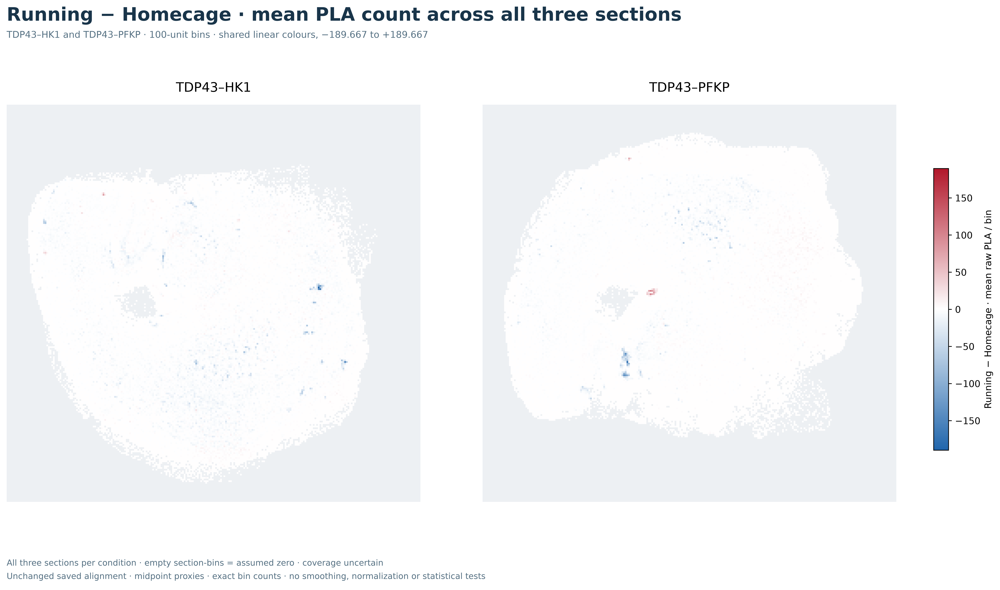

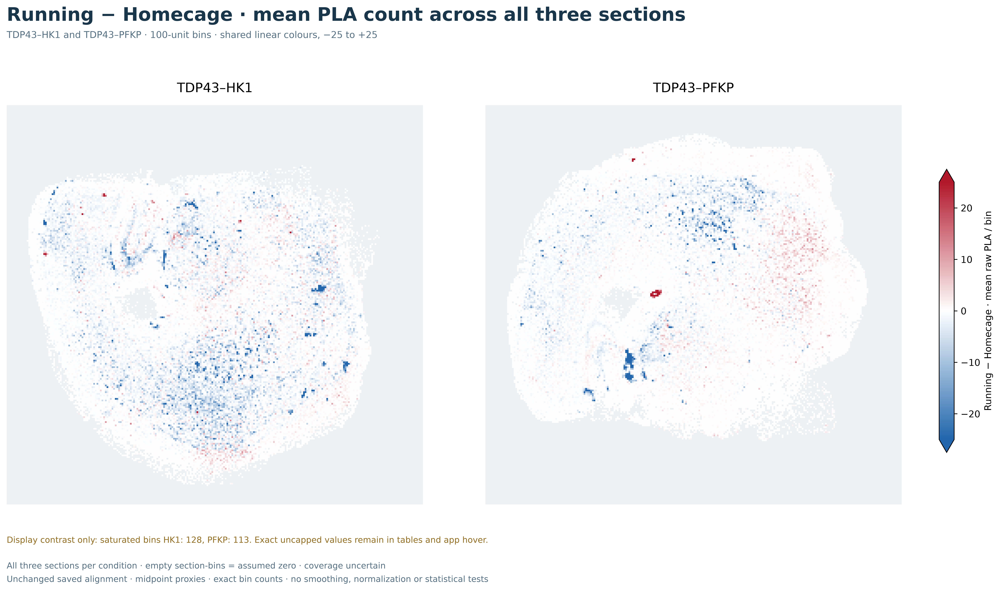

,arm,negative_difference_bins,positive_difference_bins,zero_difference_bins,fixed_section_denominator
6,HK1,14859,6943,7906,3
7,PFKP,10678,7699,11967,3


In [3]:
display(Image(filename=str(run/'figures/section_mean_differences_100.png'),width=1450))
display(Image(filename=str(run/'figures/section_mean_differences_contrast_100.png'),width=1450))
display(validation_table.query('bin_width == 100')[['arm','negative_difference_bins','positive_difference_bins','zero_difference_bins','fixed_section_denominator']])

### The two means behind each subtraction

The left and middle columns show Homecage and Running means on one shared sequential scale across both arms and conditions. The right column shows the exact subtraction with one shared signed scale. A mean of zero can include bins assumed empty under the agreed rule; **coverage remains uncertain**. These are raw counts per bin, not density per tissue area and not the former project’s ChAT-associated PLA percentage outcome.

In [4]:
display(Image(filename=str(run/'figures/section_means_and_difference_contrast_100.png'),width=1600))
print('Detail colours: means 0–25, differences ±25; saturated bins are counted in every panel. Exact values are unchanged.')
print('Full-range companion:', run/'figures/section_means_and_difference_100.png')

Detail colours: means 0–25, differences ±25; saturated bins are counted in every panel. Exact values are unchanged.
Full-range companion: /Users/adambrewer/Documents/ChatGPT/TDP43_Analysis/outputs/section_means/20261114T175717494903Z_ab4d15ecc15b/figures/section_means_and_difference_100.png


## 2 · Detailed 2D alignment and object review

**Question:** where are the detected objects in the saved aligned frame, and do apparent group features occur in more than one section?

**How to read:** each atlas shows all exported PLA midpoint proxies for one arm, with Homecage sections above Running sections. Faint background tiles mark observed PLA/ChAT support rather than tissue boundaries. Every selected PLA point is retained, with no display sampling. The app provides aligned overlays, native/fixed views and local source-object inspection. No physical Z or serial reconstruction is used.

**Evidence:** the original twelve fixed matrices are unchanged, and the original alignment-check image remains pixel-identical to its historical reference. The scientist has accepted reuse for this exploratory comparison. Reproduction checks verify computational provenance; they do not independently validate biology.

**Next:** inspect consistency across all three animals and compare group features with individual sections. Object maps establish exported locations, not fluorescence intensity, cell identity, direct molecular binding or complete tissue coverage.

In [5]:
replay = json.loads((ROOT/'outputs/comet_core/alignment_replay_validation.json').read_text())
reference = ROOT/'outputs/comet_core/figures/alignment_check_reference.png'
reproduced = ROOT/'outputs/comet_core/figures/alignment_check_reproduced.png'
assert reference.read_bytes()==reproduced.read_bytes()
assert hashlib.sha256(reference.read_bytes()).hexdigest()==replay['reference_sha256']
assert replay['transforms_unchanged'] and replay['pixel_identical_to_saved_reference']
for arm in ['hk1','pfkp']:
    display(Image(filename=str(ROOT/'outputs/comet_core/detailed_review'/('alignment_detail_'+arm+'.png')),width=1600))
print('Original fixed alignment retained. No 3D reconstruction or new fit.')

Original fixed alignment retained. No 3D reconstruction or new fit.


## 3 · Observed support, with a fixed mean denominator

**Question:** which sections contain exported objects at each location, and where does the zero assumption matter most?

**How to read:** N=0,1,2,3 are four discrete colors. N counts sections with at least one PLA or ChAT detection. N=0 means no detections; N=3 means all three sections have detections. Neither proves tissue presence or full-bin coverage. The mean denominator stays **three at every displayed location**, regardless of N. For a condition with N=1, the remaining two section-bins contribute assumed zero.

**What this supports:** an audit of detection support and sensitivity to empty-bin assumptions, alongside the requested all-three-section average. The app links selected bins to a six-section table and detailed points. **Next:** inspect whether a contrast comes from broad agreement or one section; retain the stated coverage uncertainty when reporting it.

In [6]:
display(Image(filename=str(ROOT/'outputs/comet_core/detailed_review/observed_support_detail_100.png'),width=1450))
support_rows=[]
for arm, arrays in result['resolutions']['100']['arms'].items():
    for condition,prefix in [('Homecage','homecage'),('Running','running')]:
        n=np.asarray(arrays[prefix+'_observed_section_n'])
        domain=np.asarray(arrays['displayable'],bool)
        support_rows.append({'arm':arm,'condition':condition,'mean_denominator':3,
                             **{f'displayed_bins_observed_N_{i}':int(((n==i)&domain).sum()) for i in range(4)}})
display(pd.DataFrame(support_rows))

,arm,condition,mean_denominator,displayed_bins_observed_N_0,displayed_bins_observed_N_1,displayed_bins_observed_N_2,displayed_bins_observed_N_3
0,HK1,Homecage,3,2112,3774,7009,16813
1,HK1,Running,3,2645,5222,6302,15539
2,PFKP,Homecage,3,5365,5134,5337,14508
3,PFKP,Running,3,2350,8943,7271,11780


## Scientific scope, provenance and rerun

The original instruction PDF p. 1 §§3–4 defines a different strict method: whole-bin tissue-mask containment and a mask-valid section denominator. The later scientist/user answers authorize the current mask-free fixed-three exploratory comparison. The old strict test has **not** been passed and is preserved separately; it is not a gate on the now-authorized analysis.

Inputs, assignments and exclusions are recorded in `metadata/cohort_selection.json` and `metadata/selected_section_metadata.csv`. The exact updated rule is in `metadata/scientist_directed_mean_policy.json`; scientist statements are in `docs/scientist_clarifications_2026-11-14.md`. There are no pending scientist questions for the agreed comparison. Scientific limitations remain explicit rather than converted into new asset requests.

```mermaid
flowchart LR
    A[12 completed exports, six animals] --> B[Unchanged saved alignment]
    B --> C[Per-section PLA and ChAT bin counts]
    C --> D[Sum three PLA sections / 3 per condition]
    D --> E[Running minus Homecage, arms separate]
    C --> F[Observed support and all PLA points]
    E --> G[600 DPI figures, tables and offline app]
    F --> G
```

This run reuses validated raw-count arrays by default, derives new immutable means and exports saved figures. The historical source payload is hash-checked before/after. Set `TDP43_RECOUNT_RAW=1` to recount the twelve CSVs first. The README has exact environment and execution commands. Nothing is moved, pushed or published.

In [7]:
from scripts.build_comet_core_report import build as build_report
report = build_report(ROOT)
print('Offline app rebuilt:', report)
print('600-DPI exported figures:', len(figure_manifest['figures'])+len(review['figures']))
print('Tables:', run/'resolution_100/hk1_bins.csv', 'and pfkp_bins.csv')
print('Current policy:', ROOT/'metadata/scientist_directed_mean_policy.json')
validation_path=ROOT/'outputs/validation.json'
validation=json.loads(validation_path.read_text())
validation.update(current_analysis='Scientist-directed fixed-three section means; empty bins assumed zero; coverage uncertain.',
    fixed_three_section_means_generated=True, fixed_section_denominator=3, empty_bin_policy='zero',
    tissue_coverage_verified=False, current_run_directory=str(run),
    raw_recomputed_this_execution=raw_recomputed, historical_count_source_sha256=source_sha,
    all_fixed_three_means_independently_verified=True, full_pla_point_provenance_count=310024,
    alignment_transforms_unchanged=True, high_resolution_png_dpi=600,
    current_notebook_scope='All current report cells executed using validated saved raw counts; full raw recount is optional.',
    scientist_questions_pending=0)
validation_path.write_text(json.dumps(validation,indent=2)+'\n')

Offline app rebuilt: {'status': 'exploratory_ready', 'strict_pdf_status': 'blocked', 'core_status': 'blocked', 'viewer': {'path': '/Users/adambrewer/Documents/ChatGPT/TDP43_Analysis/outputs/app/index.html', 'bytes': 76467775, 'status': 'exploratory_ready', 'strict_pdf_status': 'blocked', 'saved_alignment_sections': 12, 'resolutions': ['100', '250', '500', '1000']}}
600-DPI exported figures: 11
Tables: /Users/adambrewer/Documents/ChatGPT/TDP43_Analysis/outputs/section_means/20261114T175717494903Z_ab4d15ecc15b/resolution_100/hk1_bins.csv and pfkp_bins.csv
Current policy: /Users/adambrewer/Documents/ChatGPT/TDP43_Analysis/metadata/scientist_directed_mean_policy.json


8525